In [1]:
results = {
    "ZSRE": {
        "CMA": {
            "layer": 5,
            "Rewrite": 0.9850,
            "Rephrase": 0.8796,
            "Locality": 0.6589,
            "Portability": 0.4202,
            "Overall": 0.1473,
        },
        "Inf(ONH)": {
            "layer": 8,
            "Rewrite": 0.9862,
            "Rephrase": 0.8833,
            "Locality": 0.6857,
            "Portability": 0.3947,
            "Overall": 0.1566,
        },
        "Inf(OH)": {
            "layer": 8,
            "Rewrite": 0.9862,
            "Rephrase": 0.8833,
            "Locality": 0.6857,
            "Portability": 0.3947,
            "Overall": 0.1566,
        },
        "Inf(Q)": {
            "layer": 8,
            "Rewrite": 0.9862,
            "Rephrase": 0.8833,
            "Locality": 0.6857,
            "Portability": 0.3947,
            "Overall": 0.1566,
        },
    },

    "WikiBio": {
        "CMA": {
            "layer": 6,
            "Rewrite": 0.8258,
            "Locality": 0.3894,
            "Fluency": 6.1483,
            "Overall": 0.4746,
        },
        "Inf(ONH)": {
            "layer": 12,
            "Rewrite": 0.8433,
            "Locality": 0.2793,
            "Fluency": 6.3199,
            "Overall": 0.2452,
        },
        "Inf(OH)": {
            "layer": 12,
            "Rewrite": 0.8433,
            "Locality": 0.2793,
            "Fluency": 6.3199,
            "Overall": 0.2452,
        },
        "Inf(Q)": {
            "layer": 12,
            "Rewrite": 0.8433,
            "Locality": 0.2793,
            "Fluency": 6.3199,
            "Overall": 0.2452,
        },
    },

    "WikiCounterfact": {
        "CMA": {
            "layer": 6,
            "Rewrite": 0.9713,
            "Locality": 0.3931,
            "Portability": 0.2695,
            "Fluency": 5.4215,
            "Overall": 0.3049,
        },
        "Inf(ONH)": {
            "layer": 11,
            "Rewrite": 0.9841,
            "Locality": 0.4075,
            "Portability": 0.2831,
            "Fluency": 5.5982,
            "Overall": 0.3371,
        },
        "Inf(OH)": {
            "layer": 11,
            "Rewrite": 0.9841,
            "Locality": 0.4075,
            "Portability": 0.2831,
            "Fluency": 5.5982,
            "Overall": 0.3371,
        },
        "Inf(Q)": {
            "layer": 11,
            "Rewrite": 0.9841,
            "Locality": 0.4075,
            "Portability": 0.2831,
            "Fluency": 5.5982,
            "Overall": 0.3371,
        },
    },

    "WikiRecent": {
        "CMA": {
            "layer": 6,
            "Rewrite": 0.9837,
            "Locality": 0.5029,
            "Portability": 0.2979,
            "Fluency": 5.7429,
            "Overall": 0.4724,
        },
        "Inf(ONH)": {
            "layer": 11,
            "Rewrite": 0.9892,
            "Locality": 0.5199,
            "Portability": 0.3044,
            "Fluency": 5.6955,
            "Overall": 0.5116,
        },
        "Inf(OH)": {
            "layer": 11,
            "Rewrite": 0.9892,
            "Locality": 0.5199,
            "Portability": 0.3044,
            "Fluency": 5.6955,
            "Overall": 0.5116,
        },
        "Inf(Q)": {
            "layer": 45,
            "Rewrite": 0.5088,
            "Locality": 0.7570,
            "Portability": 0.2203,
            "Fluency": 5.6844,
            "Overall": 0.3934,
        },
    },
}


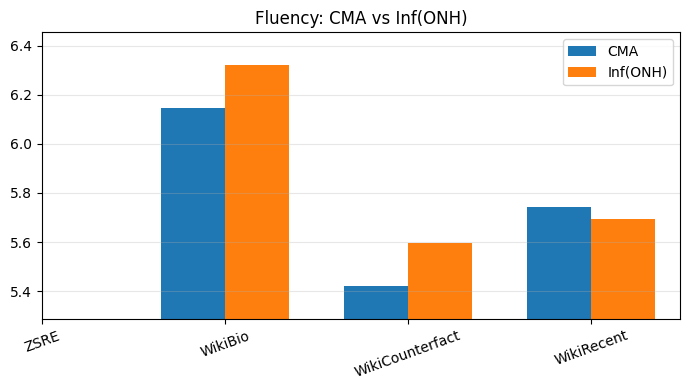

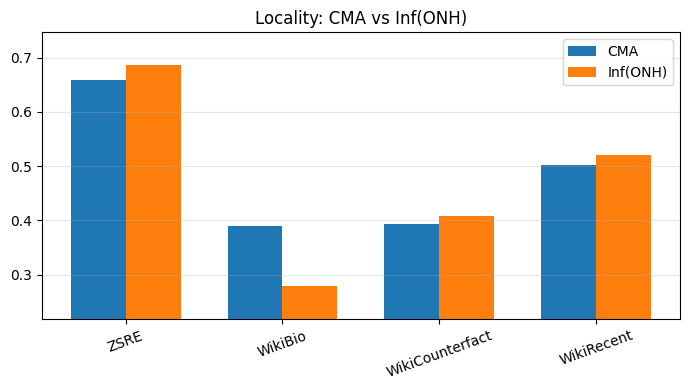

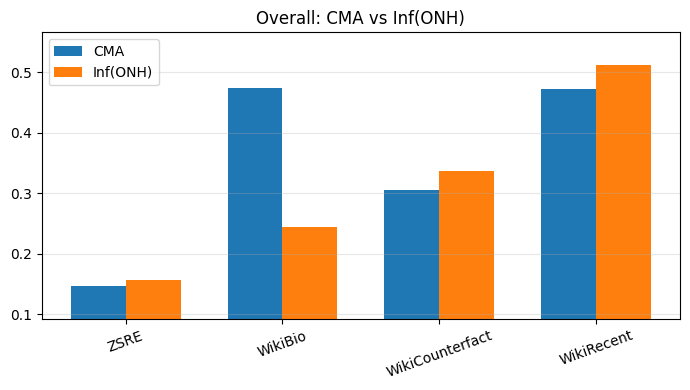

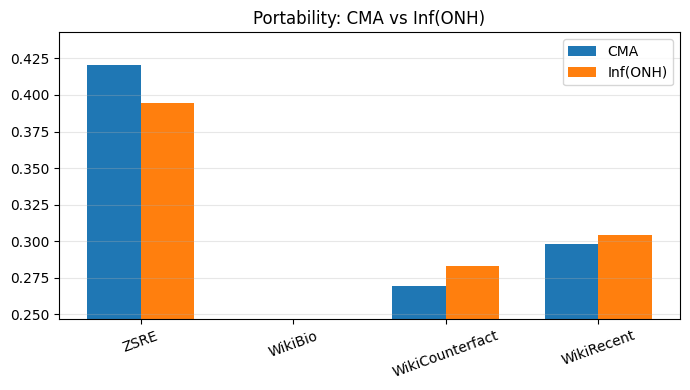

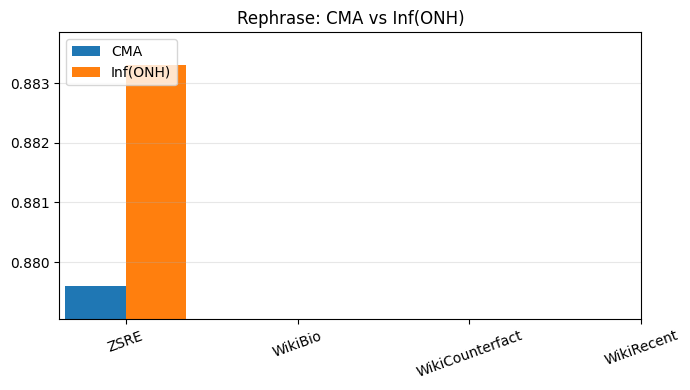

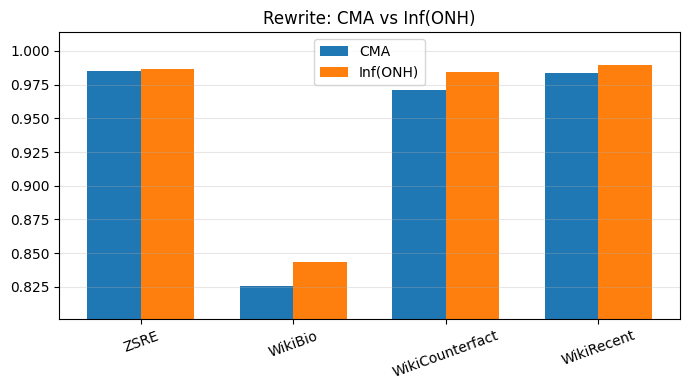

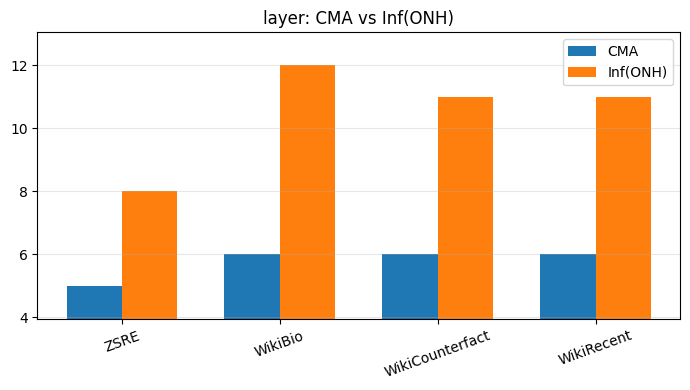

In [2]:
import matplotlib.pyplot as plt
import numpy as np

def auto_ylim(values, pad_ratio=0.15, min_range=1e-3):
    """
    Compute adaptive y-limits for clearer visualization.
    """
    values = np.asarray(values)
    values = values[np.isfinite(values)]

    vmin, vmax = values.min(), values.max()
    vrange = max(vmax - vmin, min_range)

    pad = pad_ratio * vrange
    return vmin - pad, vmax + pad


metrics = sorted(
    {m for d in results.values() for k in d.values() for m in k}
)

datasets = list(results.keys())
methods = ["CMA", "Inf(ONH)"]

for metric in metrics:
    fig, ax = plt.subplots(figsize=(7, 4))

    x = np.arange(len(datasets))
    width = 0.35

    cma_vals = np.array([
        results[d].get("CMA", {}).get(metric, np.nan) for d in datasets
    ])
    inf_vals = np.array([
        results[d].get("Inf(ONH)", {}).get(metric, np.nan) for d in datasets
    ])

    ax.bar(x - width/2, cma_vals, width, label="CMA")
    ax.bar(x + width/2, inf_vals, width, label="Inf(ONH)")

    # === adaptive y-limits ===
    ymin, ymax = auto_ylim(np.concatenate([cma_vals, inf_vals]))
    ax.set_ylim(ymin, ymax)

    ax.set_xticks(x)
    ax.set_xticklabels(datasets, rotation=20)
    ax.set_title(f"{metric}: CMA vs Inf(ONH)")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    # plt.savefig(f"{metric}_CMA_vs_InfONH.png", dpi=300)
    plt.show()

In [3]:
import numpy as np

def normalize_per_dataset(values):
    """
    Min-max normalize to [0,1] within a dataset.
    """
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)

    vmin, vmax = values[mask].min(), values[mask].max()
    if vmax - vmin < 1e-8:
        return np.zeros_like(values)

    values[mask] = (values[mask] - vmin) / (vmax - vmin)
    return values


/tmp/ipykernel_3683946/2653121592.py:9: RuntimeWarning: All-NaN slice encountered
  vmin, vmax = np.nanmin(values), np.nanmax(values)


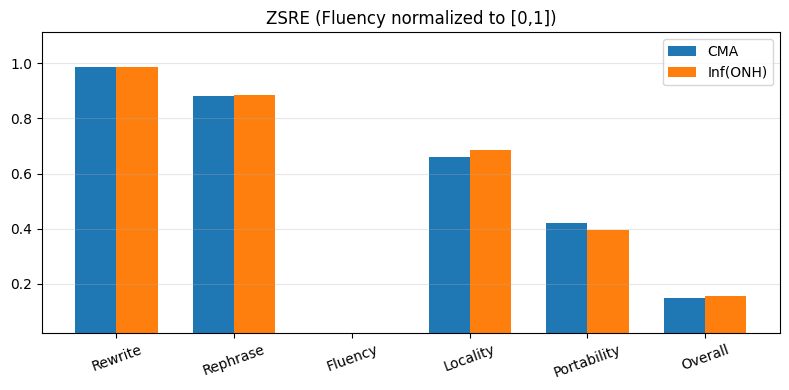

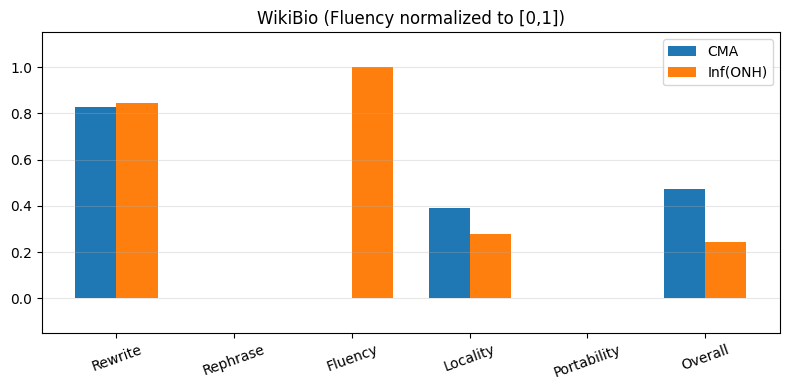

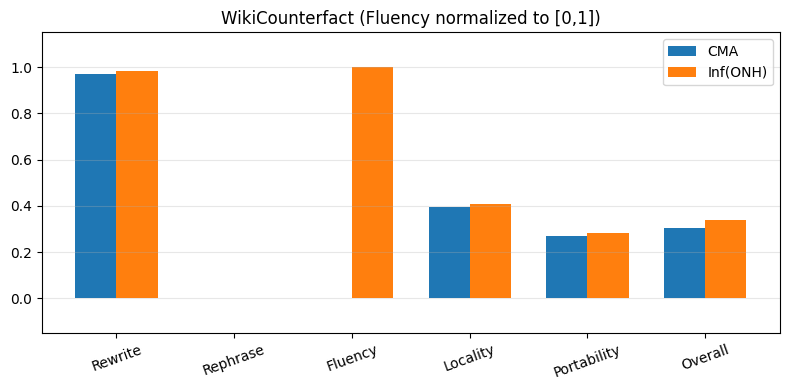

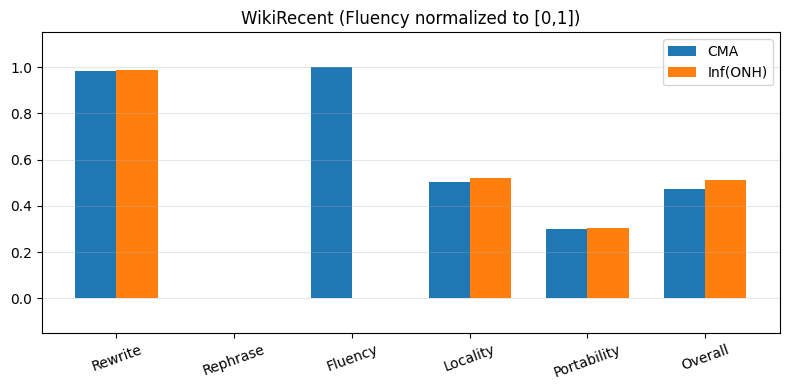

In [4]:
import numpy as np
import matplotlib.pyplot as plt

metrics = ["Rewrite", "Rephrase", "Fluency", "Locality", "Portability", "Overall"]
methods = ["CMA", "Inf(ONH)"]

def normalize(values):
    values = np.asarray(values, dtype=float)
    vmin, vmax = np.nanmin(values), np.nanmax(values)
    if vmax - vmin < 1e-8:
        return np.zeros_like(values)
    return (values - vmin) / (vmax - vmin)

def auto_ylim(values, pad_ratio=0.15):
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    vmin, vmax = values.min(), values.max()
    pad = (vmax - vmin) * pad_ratio if vmax > vmin else 0.1
    return vmin - pad, vmax + pad


for dataset, dataset_results in results.items():
    fig, ax = plt.subplots(figsize=(8, 4))

    x = np.arange(len(metrics))
    width = 0.35

    cma_vals = []
    inf_vals = []

    for metric in metrics:
        cma_vals.append(dataset_results.get("CMA", {}).get(metric, np.nan))
        inf_vals.append(dataset_results.get("Inf(ONH)", {}).get(metric, np.nan))

    cma_vals = np.array(cma_vals, dtype=float)
    inf_vals = np.array(inf_vals, dtype=float)

    # === normalize fluency only (within this dataset) ===
    fluency_idx = metrics.index("Fluency")
    fluency_pair = normalize([cma_vals[fluency_idx], inf_vals[fluency_idx]])
    cma_vals[fluency_idx], inf_vals[fluency_idx] = fluency_pair

    ax.bar(x - width/2, cma_vals, width, label="CMA")
    ax.bar(x + width/2, inf_vals, width, label="Inf(ONH)")

    ymin, ymax = auto_ylim(np.concatenate([cma_vals, inf_vals]))
    ax.set_ylim(ymin, ymax)

    ax.set_xticks(x)
    ax.set_xticklabels(metrics, rotation=20)
    ax.set_title(f"{dataset} (Fluency normalized to [0,1])")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()


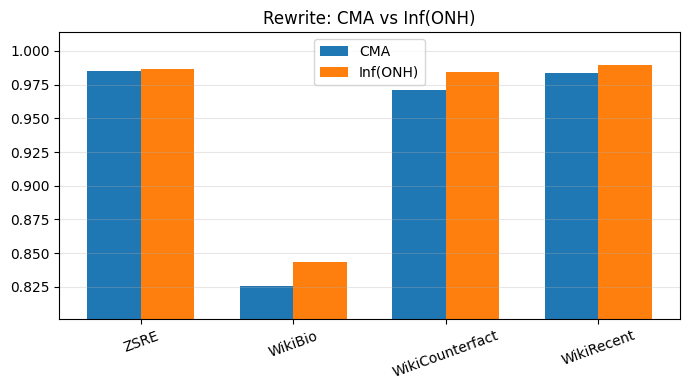

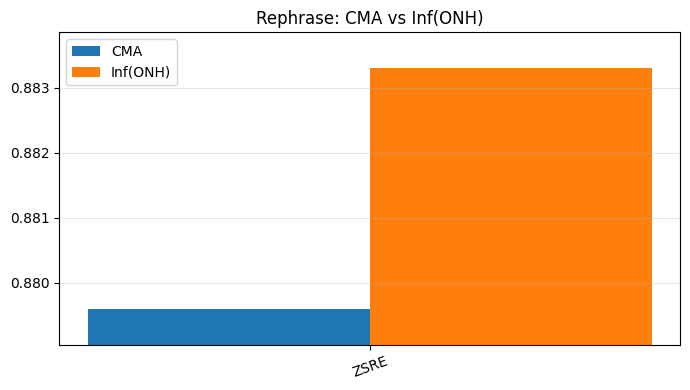

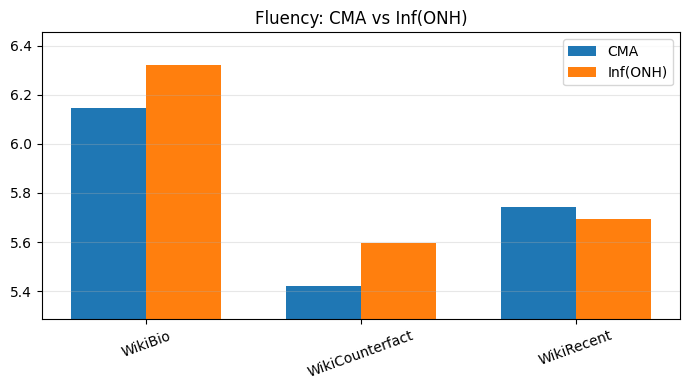

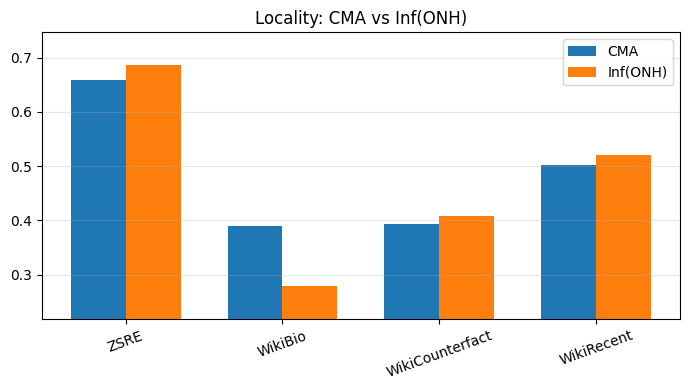

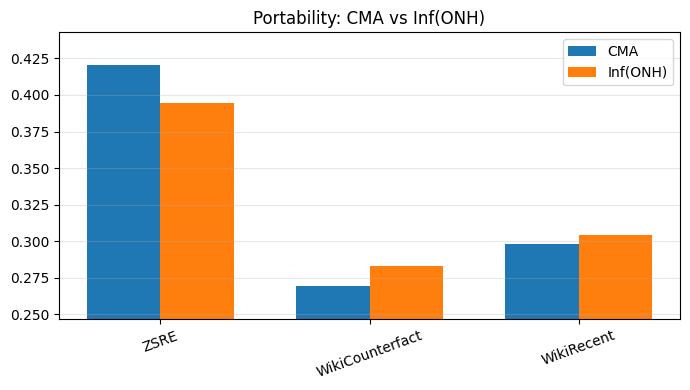

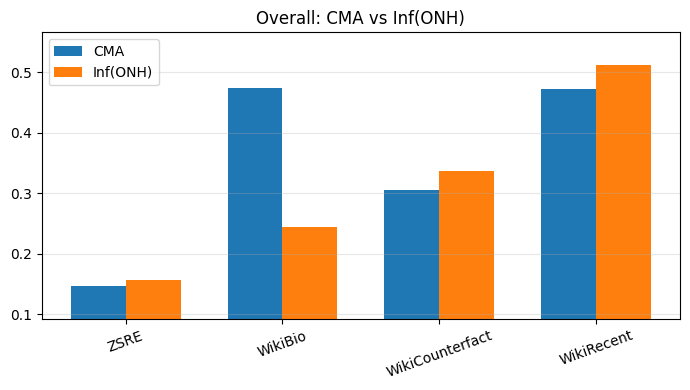

In [5]:

for metric in metrics:
    # Filter datasets that have valid values for both methods
    valid_datasets = [
        d for d in datasets
        if np.isfinite(results[d].get("CMA", {}).get(metric, np.nan)) and
           np.isfinite(results[d].get("Inf(ONH)", {}).get(metric, np.nan))
    ]
    
    if not valid_datasets:
        continue  # Skip metric if no datasets are valid

    fig, ax = plt.subplots(figsize=(7, 4))
    x = np.arange(len(valid_datasets))
    width = 0.35

    cma_vals = np.array([results[d]["CMA"][metric] for d in valid_datasets])
    inf_vals = np.array([results[d]["Inf(ONH)"][metric] for d in valid_datasets])

    ax.bar(x - width/2, cma_vals, width, label="CMA")
    ax.bar(x + width/2, inf_vals, width, label="Inf(ONH)")

    # Adaptive y-limits
    ymin, ymax = auto_ylim(np.concatenate([cma_vals, inf_vals]))
    ax.set_ylim(ymin, ymax)

    ax.set_xticks(x)
    ax.set_xticklabels(valid_datasets, rotation=20)
    ax.set_title(f"{metric}: CMA vs Inf(ONH)")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()


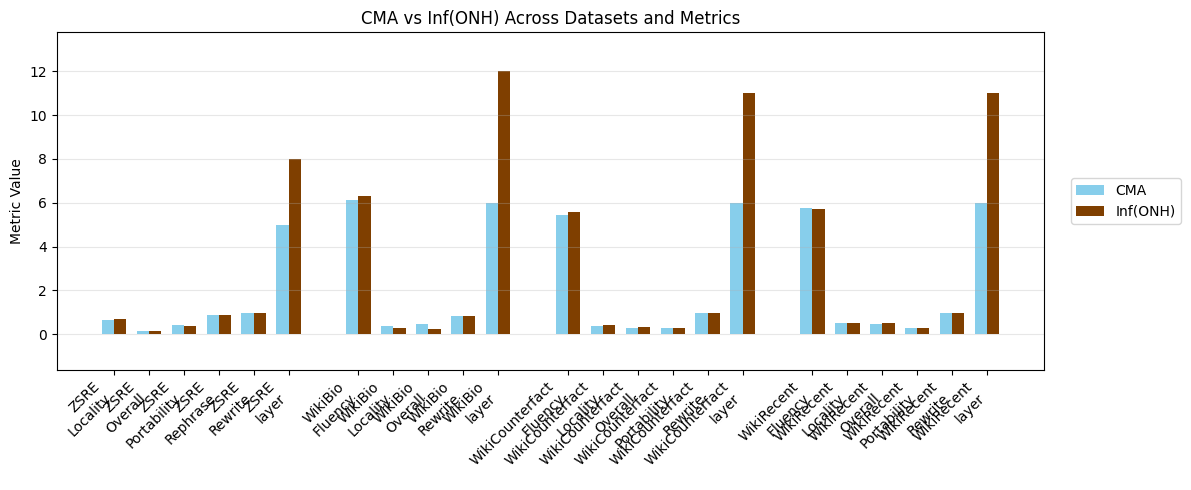

In [6]:
import matplotlib.pyplot as plt
import numpy as np

def auto_ylim(values, pad_ratio=0.15, min_range=1e-3):
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return 0, 1  # fallback
    vmin, vmax = values.min(), values.max()
    vrange = max(vmax - vmin, min_range)
    pad = pad_ratio * vrange
    return vmin - pad, vmax + pad

# --- Prepare data ---
metrics = sorted(
    {m for d in results.values() for k in d.values() for m in k}
)
methods = ["CMA", "Inf(ONH)"]

# Filter datasets that have valid values for at least one method
all_datasets = list(results.keys())

# --- Plot ---
fig, ax = plt.subplots(figsize=(12, 5))

bar_width = 0.35
x_base = 0
xticks = []
xtick_labels = []

colors = {
    "CMA": "skyblue",
    "Inf(ONH)": "#7F3F00"  # dark brown
}

for dataset in all_datasets:
    # Filter metrics that exist for this dataset
    valid_metrics = [
        m for m in metrics
        if np.isfinite(results[dataset].get("CMA", {}).get(m, np.nan)) and
           np.isfinite(results[dataset].get("Inf(ONH)", {}).get(m, np.nan))
    ]
    
    if not valid_metrics:
        continue
    
    x = np.arange(len(valid_metrics)) + x_base
    cma_vals = np.array([results[dataset]["CMA"][m] for m in valid_metrics])
    inf_vals = np.array([results[dataset]["Inf(ONH)"][m] for m in valid_metrics])

    # Plot bars
    ax.bar(x - bar_width/2, cma_vals, bar_width, color=colors["CMA"])
    ax.bar(x + bar_width/2, inf_vals, bar_width, color=colors["Inf(ONH)"])

    # Update x positions and labels
    xticks.extend(x)
    xtick_labels.extend([f"{dataset}\n{m}" for m in valid_metrics])
    
    # Shift x_base for next dataset
    x_base += len(valid_metrics) + 1  # +1 for spacing between datasets

# Adaptive y-limits
all_vals = [results[d][mth][m] 
            for d in all_datasets 
            for mth in methods 
            for m in metrics
            if m in results[d][mth] and np.isfinite(results[d][mth][m])]
ymin, ymax = auto_ylim(np.array(all_vals))
ax.set_ylim(ymin, ymax)

# X-axis labels
ax.set_xticks(xticks)
ax.set_xticklabels(xtick_labels, rotation=45, ha="right")

# Grid
ax.grid(axis="y", alpha=0.3)

# Legend on the side
ax.legend(methods, loc='center left', bbox_to_anchor=(1.02, 0.5))

ax.set_ylabel("Metric Value")
ax.set_title("CMA vs Inf(ONH) Across Datasets and Metrics")

plt.tight_layout()
plt.show()


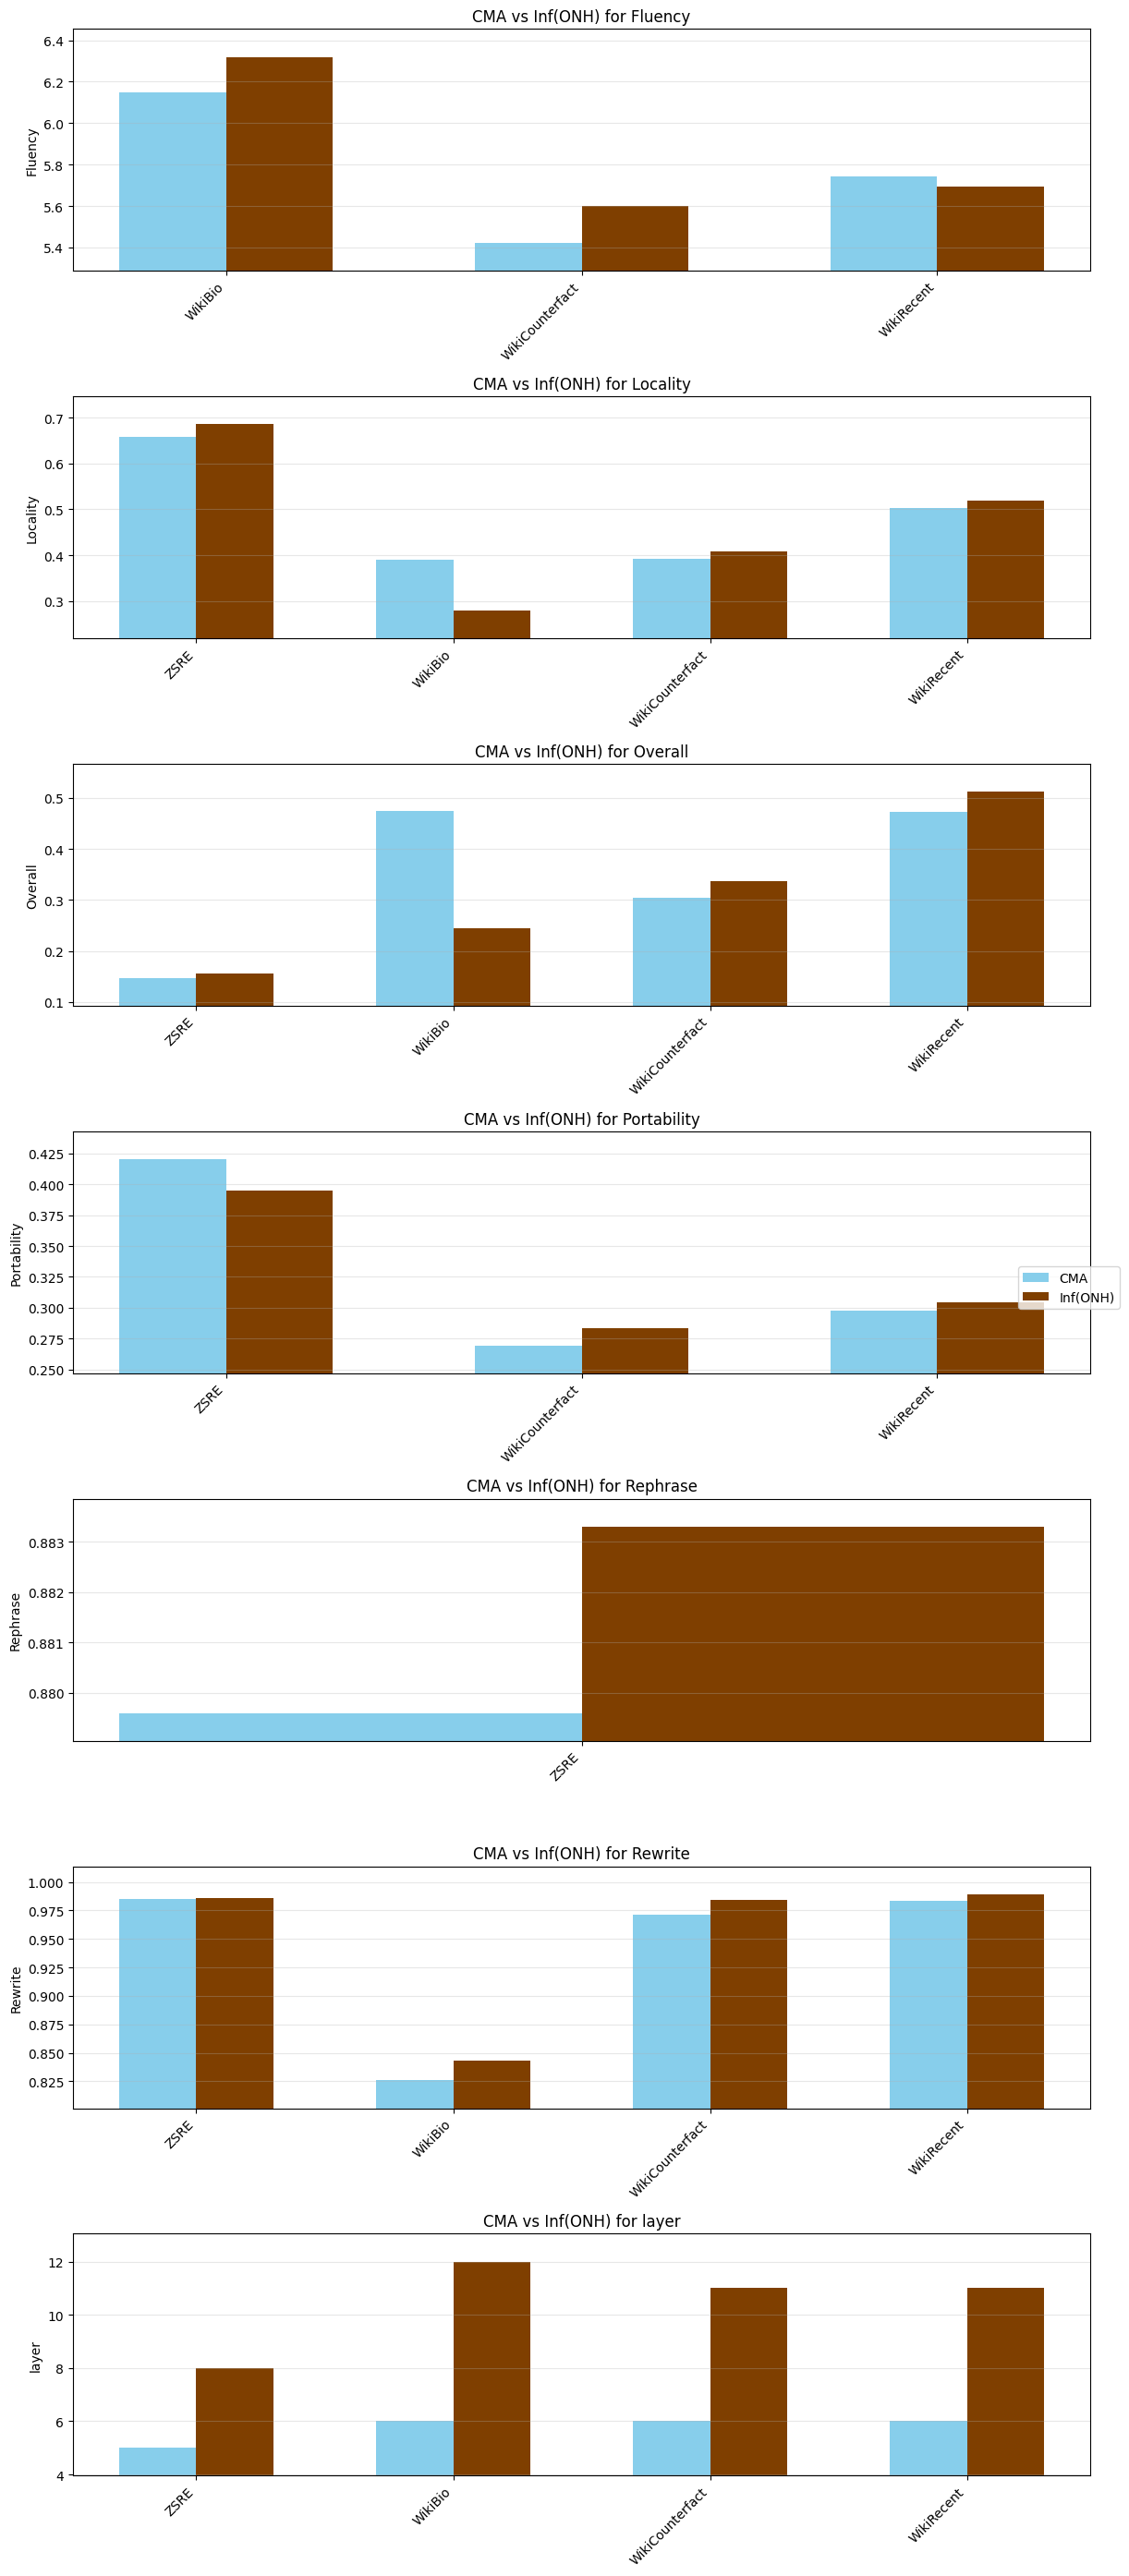

In [7]:
import matplotlib.pyplot as plt
import numpy as np

def auto_ylim(values, pad_ratio=0.15, min_range=1e-3):
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return 0, 1
    vmin, vmax = values.min(), values.max()
    vrange = max(vmax - vmin, min_range)
    pad = pad_ratio * vrange
    return vmin - pad, vmax + pad

methods = ["CMA", "Inf(ONH)"]
colors = {"CMA": "skyblue", "Inf(ONH)": "#7F3F00"}  # dark brown

datasets = list(results.keys())
metrics = sorted({m for d in results.values() for k in d.values() for m in k})

# --- Create figure with subplots for each metric ---
fig, axes = plt.subplots(len(metrics), 1, figsize=(12, 4 * len(metrics)), sharex=False)

if len(metrics) == 1:
    axes = [axes]  # Ensure iterable

for ax, metric in zip(axes, metrics):
    x_base = 0
    xticks = []
    xtick_labels = []

    for dataset in datasets:
        # Skip datasets without this metric for both methods
        if not all(np.isfinite(results[dataset].get(mth, {}).get(metric, np.nan)) for mth in methods):
            continue

        x = np.arange(1) + x_base  # one bar group per dataset
        cma_val = results[dataset]["CMA"][metric]
        inf_val = results[dataset]["Inf(ONH)"][metric]

        ax.bar(x - 0.15, cma_val, 0.3, color=colors["CMA"])
        ax.bar(x + 0.15, inf_val, 0.3, color=colors["Inf(ONH)"])

        xticks.append(x)
        xtick_labels.append(dataset)

        x_base += 1  # shift for next dataset

    xticks = [xi[0] for xi in xticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels(xtick_labels, rotation=45, ha="right")

    # Adaptive y-limits for this metric
    vals = [results[d][mth][metric] for d in datasets for mth in methods
            if np.isfinite(results[d].get(mth, {}).get(metric, np.nan))]
    ymin, ymax = auto_ylim(vals)
    ax.set_ylim(ymin, ymax)

    ax.set_ylabel(metric)
    ax.set_title(f"CMA vs Inf(ONH) for {metric}")
    ax.grid(axis="y", alpha=0.3)

# Legend on the side
fig.legend(methods, loc='center right', bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()



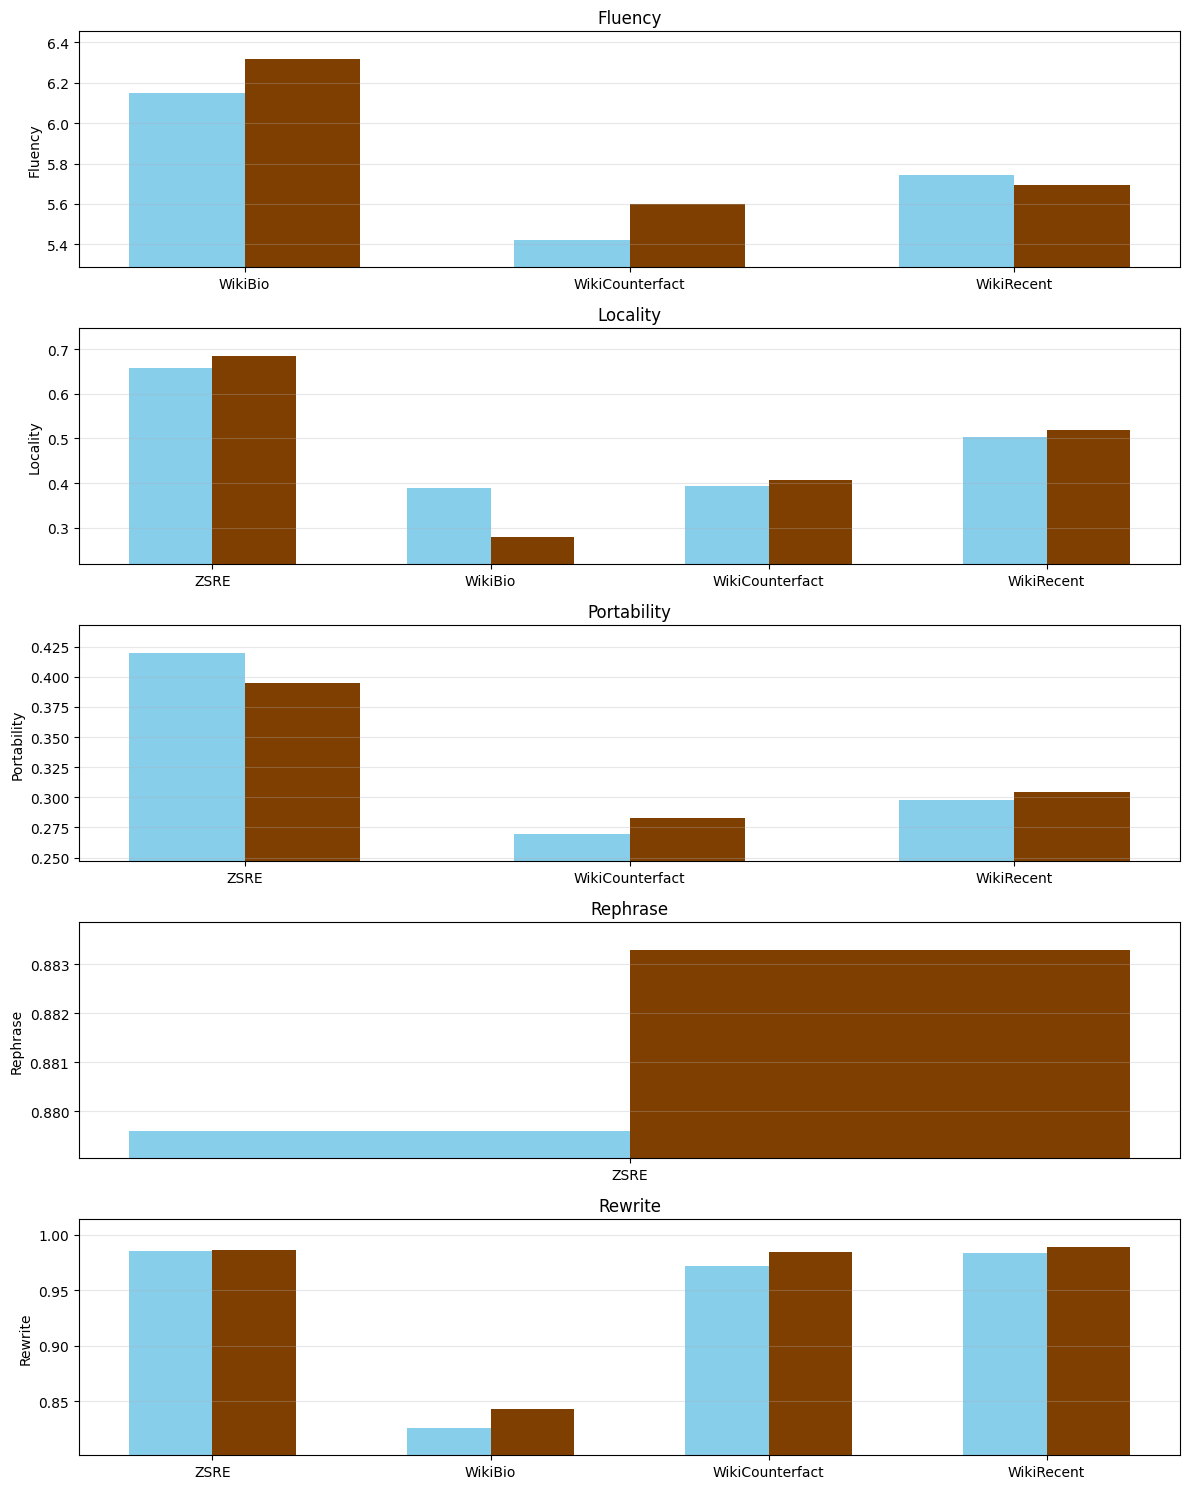

In [12]:
import matplotlib.pyplot as plt
import numpy as np

def auto_ylim(values, pad_ratio=0.15, min_range=1e-3):
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return 0, 1
    vmin, vmax = values.min(), values.max()
    vrange = max(vmax - vmin, min_range)
    pad = pad_ratio * vrange
    return vmin - pad, vmax + pad

methods = ["CMA", "Inf(ONH)"]
colors = {"CMA": "skyblue", "Inf(ONH)": "#7F3F00"}  # dark brown

datasets = list(results.keys())
# Exclude "Overall"
metrics = sorted({m for d in results.values() for k in d.values() for m in k if ((m != "Overall") and (m != "layer"))})

# --- Create figure with subplots for each metric ---
fig, axes = plt.subplots(len(metrics), 1, figsize=(12, 3 * len(metrics)), sharex=False)
plt.subplots_adjust(hspace=0.05)  # Minimal space between plots

if len(metrics) == 1:
    axes = [axes]  # Ensure iterable

for ax, metric in zip(axes, metrics):
    x_base = 0
    xticks = []
    xtick_labels = []

    for dataset in datasets:
        # Skip datasets without this metric for both methods
        if not all(np.isfinite(results[dataset].get(mth, {}).get(metric, np.nan)) for mth in methods):
            continue

        x = np.arange(1) + x_base  # one bar group per dataset
        cma_val = results[dataset]["CMA"][metric]
        inf_val = results[dataset]["Inf(ONH)"][metric]

        ax.bar(x - 0.15, cma_val, 0.3, color=colors["CMA"])
        ax.bar(x + 0.15, inf_val, 0.3, color=colors["Inf(ONH)"])

        xticks.append(x)
        xtick_labels.append(dataset)

        x_base += 1  # shift for next dataset

    xticks = [xi[0] for xi in xticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels(xtick_labels, rotation=0, ha="center")  # Horizontal labels

    # Adaptive y-limits for this metric
    vals = [results[d][mth][metric] for d in datasets for mth in methods
            if np.isfinite(results[d].get(mth, {}).get(metric, np.nan))]
    ymin, ymax = auto_ylim(vals)
    ax.set_ylim(ymin, ymax)

    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
#save the figure
plt.savefig("filename.png", dpi=300, bbox_inches="tight")

plt.show()
